# Limit Order Book Alpha Research

Exploration of the LOBSTER order-book dataset.

In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from __future__ import annotations

from dataclasses import asdict, dataclass
from itertools import zip_longest

import json
import logging
import argparse
import joblib

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline


from sklearn.ensemble import (HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error,mean_squared_error,)

# Make DataFrames easier to inspect inside Jupyter
#pd.set_option("display.max_columns", 100)
#pd.set_option("display.width", 180)

print("Imports completed successfully.")

Imports completed successfully.


In [104]:
@dataclass(frozen=True)
class Config:
    level: int =5 # read the first five price levels
    event_stride: int=1 # keep every 5th order book to keep the memory usage minimal
    latency_rows: int=10
    horizon_rows: int=100 # exit ater this many sampled events from the entry points
    commission_bps_per_side: float=0.00
    slippage_ticks_per_side: float=1.0
    tick_size_dollars: float=0.01
    
    notional_dollars: float=10_000.0 #fixed allocation
    minimum_validation_trades: int=5

    flow_windows: tuple[int, ...] = (20, 100, 500)
    random_state: int=42
    chunk_size: int=500_000
    


In [27]:
def orderbook_columns(level: int) -> list[str]:
    columns=[]
    for level in range(1, level+1):
        columns.extend([f"ask_price_{level}", f"ask_size_{level}", f"bid_price_{level}", f"bid_size_{level}"])
    return columns
orderbook_columns(5)    

['ask_price_1',
 'ask_size_1',
 'bid_price_1',
 'bid_size_1',
 'ask_price_2',
 'ask_size_2',
 'bid_price_2',
 'bid_size_2',
 'ask_price_3',
 'ask_size_3',
 'bid_price_3',
 'bid_size_3',
 'ask_price_4',
 'ask_size_4',
 'bid_price_4',
 'bid_size_4',
 'ask_price_5',
 'ask_size_5',
 'bid_price_5',
 'bid_size_5']

In [28]:

# this is for loading he data, making sure the messege and bookorder 
#rows are matched 


def read_lobster(orederbook_path: Path, message_path: Path, config: Config) -> pd.DataFrame:
    columns= orderbook_columns(config.level)
    message_columns= ["seconds", "event_type", "order_id", "message_size", "message_price", "direction" ]
    parts=[]
    row_offset= 0
    orderbook_reader = pd.read_csv(orderbook_path, header=None, usecols=range(4 * config.level),
        chunksize=config.chunk_size,)

    message_reader = pd.read_csv(message_path, header=None, usecols=range(6),chunksize=config.chunk_size,)

    for book_chunk, message_chunk in zip_longest(orderbook_reader,message_reader,):
        if book_chunk is None or message_chunk is None:
            raise ValueError("The order-book and message files have different row counts.")

        if len(book_chunk) != len(message_chunk):
            raise ValueError("The order-book and message chunks are not aligned.")

        book_chunk.columns = columns
        message_chunk.columns = message_columns

        global_rows = row_offset + np.arange(len(book_chunk))
        keep = global_rows % config.event_stride == 0
        selected = np.flatnonzero(keep)

        sampled_book = book_chunk.iloc[selected].copy()
        sampled_message = message_chunk.iloc[selected]

        sampled_book.insert(0, "event_number", global_rows[selected])
        sampled_book.insert(1, "seconds", sampled_message["seconds"].to_numpy())
        for column in message_columns[1:]:
            sampled_book[column] = (sampled_message[column].to_numpy())

        parts.append(sampled_book)

        row_offset += len(book_chunk)

    if not parts:
        raise ValueError("No data were read.")

    data = pd.concat(parts, ignore_index=True)

    logging.info(
        "Loaded %d sampled snapshots from %d original events.",
        len(data),
        row_offset,
    )

    return data
    

In [29]:




def depth_vwap(
    price_frame: pd.DataFrame,
    size_frame: pd.DataFrame,
    shares: pd.Series,
    is_buy: bool,
    extra_slippage_dollars: float,
) -> pd.Series:
    """
    Execute a fixed number of shares against displayed book depth.

    For a buy, consume ask levels from best to worst.
    For a sell, consume bid levels from best to worst.

    Returns NaN if the displayed levels cannot fill the order.
    """

    prices = price_frame.to_numpy(dtype="float64")
    sizes = size_frame.to_numpy(dtype="float64")
    requested = shares.to_numpy(dtype="float64")

    remaining = requested.copy()
    filled = np.zeros(len(price_frame), dtype="float64")
    dollar_value = np.zeros(len(price_frame), dtype="float64")

    for level in range(prices.shape[1]):
        available = np.maximum(sizes[:, level], 0.0)
        quantity = np.minimum(available, remaining)

        dollar_value += quantity * prices[:, level]
        filled += quantity
        remaining -= quantity

    with np.errstate(divide="ignore", invalid="ignore"):
        vwap = dollar_value / filled

    completely_filled = (
        np.isfinite(requested)
        & (requested > 0)
        & (remaining <= 1e-9)
        & (filled > 0)
    )

    vwap[~completely_filled] = np.nan

    if is_buy:
        vwap = vwap + extra_slippage_dollars
    else:
        vwap = vwap - extra_slippage_dollars

    return pd.Series(vwap, index=price_frame.index)

In [123]:

# here we are creating the panda dataframe with the relevant features
#from the bookorder file


def build_research_frame(raw: pd.DataFrame,config: Config,) -> tuple[pd.DataFrame, list[str]]:
    data = raw.copy()
    price_columns = [column for column in data.columns if column.startswith("ask_price_") or column.startswith("bid_price") ]

    # LOBSTER equity prices are stored in units of 1/10,000 dollars.
    for column in price_columns:
        data[column] = data[column].astype("float64") / 10_000.0

    data["message_price"] = (data["message_price"].astype("float64") / 10_000.0)
    
    # Remove locked, crossed, missing, or sentinel-value snapshots.
    valid = ((data["bid_price_1"] > 0) & (data["ask_price_1"] > data["bid_price_1"])
        & (data["ask_price_1"] < 900_000))

    invalid_fraction = 1.0 - valid.mean()

    if invalid_fraction > 0.01:
        logging.warning( "%.3f%% of snapshots failed book validation.",100 * invalid_fraction,)

    data = data.loc[valid].reset_index(drop=True)

    mid = (data["ask_price_1"] + data["bid_price_1"]) / 2.0

    microprice = (data["ask_price_1"] * data["bid_size_1"]+ data["bid_price_1"] * data["ask_size_1"]) / (data["bid_size_1"] + data["ask_size_1"]).replace(0, np.nan)

    features = pd.DataFrame(index=data.index)

    features["spread_bps"] = (10_000 * (data["ask_price_1"] - data["bid_price_1"]) / mid)

    features["microprice_deviation_bps"] = (10_000 * (microprice - mid) / mid)

    # Cumulative imbalance at multiple depths.
    depths = sorted(set([1, min(3, config.level), config.level]))

    for depth in depths:
        bid_depth = sum(data[f"bid_size_{level}"]for level in range(1, depth + 1))

        ask_depth = sum(data[f"ask_size_{level}"]for level in range(1, depth + 1))

        denominator = (bid_depth + ask_depth).replace(0, np.nan)

        features[f"imbalance_{depth}"] = (bid_depth - ask_depth) / denominator

        features[f"log_bid_depth_{depth}"] = np.log1p(bid_depth)
        features[f"log_ask_depth_{depth}"] = np.log1p(ask_depth)

    # Give more importance to queues near the touch.
    weights = {level: 1.0 / level for level in range(1, config.level + 1)}

    weighted_bid = sum(weights[level] * data[f"bid_size_{level}"]
        for level in range(1, config.level + 1))

    weighted_ask = sum(weights[level] * data[f"ask_size_{level}"]
        for level in range(1, config.level + 1))

    features["weighted_imbalance"] = (weighted_bid - weighted_ask)/ (weighted_bid + weighted_ask).replace(0, np.nan)

    # Price distance of each book level from the midpoint.
    for level in range(1, config.level + 1):
        features[f"ask_gap_{level}_bps"] = (10_000 * (data[f"ask_price_{level}"] - mid) / mid)

        features[f"bid_gap_{level}_bps"] = (10_000 * (mid - data[f"bid_price_{level}"]) / mid)

    log_mid = np.log(mid)
    one_event_return = 10_000 * log_mid.diff()

    features["mid_return_1"] = one_event_return
    features["mid_return_5"] = 10_000 * log_mid.diff(5)
    features["mid_return_20"] = 10_000 * log_mid.diff(20)

    features["realized_volatility_20"] = (one_event_return.rolling(20).std())
    
    features["realized_volatility_100"] = (one_event_return.rolling(100).std())

    features["imbalance_change_1"] = (features["imbalance_1"].diff())

    features["imbalance_change_10"] = (features["imbalance_1"].diff(10))

    event_time_difference_ms = (1_000 * data["seconds"].diff().clip(lower=0, upper=5))

    features["log_event_time_ms"] = np.log1p(event_time_difference_ms)

    # Message_book flow

    event_type = data["event_type"].astype(int)
    direction = data["direction"].astype(float).fillna(0.0)
    message_size = (data["message_size"].astype(float).fillna(0.0) )

    is_submission = event_type.eq(1)
    is_cancellation = event_type.isin([2, 3])
    is_execution = event_type.isin([4, 5])

    signed_trade_flow = pd.Series(np.where(is_execution,-direction * message_size,0.0,),index=data.index,)

    absolute_trade_flow = pd.Series(np.where(is_execution, message_size, 0.0,), index=data.index,)

    signed_submission_flow = pd.Series(np.where(is_submission, direction * message_size, 0.0,),index=data.index,)

    absolute_submission_flow = pd.Series(np.where(is_submission,message_size,0.0,),index=data.index,)

    signed_cancellation_pressure = pd.Series(np.where(is_cancellation,-direction * message_size,0.0,),index=data.index,)

    absolute_cancellation_flow = pd.Series(np.where(is_cancellation,message_size,0.0,),index=data.index,)

    signed_total_pressure = (signed_trade_flow + signed_submission_flow + signed_cancellation_pressure)

    absolute_total_flow = (absolute_trade_flow + absolute_submission_flow + absolute_cancellation_flow)

    def rolling_normalized_flow(
        signed_flow: pd.Series,
        absolute_flow: pd.Series,
        window: int,
    ) -> pd.Series:
        numerator = signed_flow.rolling(window, min_periods=window,).sum()

        denominator = absolute_flow.rolling(window, min_periods=window,).sum()

        result = numerator / denominator.where(denominator > 0)

        # A complete window with no corresponding messages
        # has neutral imbalance rather than missing data.
        result = result.mask(denominator.eq(0),0.0,)

        return result

    for window in config.flow_windows:
        features[f"trade_imbalance_{window}"] = (
            rolling_normalized_flow(signed_trade_flow, absolute_trade_flow, window,))

        features[f"submission_imbalance_{window}"] = (
            rolling_normalized_flow(signed_submission_flow, absolute_submission_flow, window,))

        features[f"cancellation_pressure_{window}"] = (
            rolling_normalized_flow(signed_cancellation_pressure, absolute_cancellation_flow, window,))

        features[f"net_message_pressure_{window}"] = (
            rolling_normalized_flow(signed_total_pressure, absolute_total_flow,window,))

        features[f"execution_fraction_{window}"] = (
            is_execution.astype(float).rolling(window,min_periods=window,).mean())

        features[f"cancellation_fraction_{window}"] = (
            is_cancellation.astype(float).rolling(window,min_periods=window,).mean())

        elapsed_seconds = (data["seconds"] - data["seconds"].shift(window)).clip(lower=1e-6)

        features[f"event_rate_{window}"] = (window / elapsed_seconds)
    


    #best-level order flow imbalance
    bid_price = data["bid_price_1"]
    ask_price = data["ask_price_1"]
    bid_size = data["bid_size_1"].astype(float)
    ask_size = data["ask_size_1"].astype(float)

    previous_bid_price = bid_price.shift(1)
    previous_ask_price = ask_price.shift(1)
    previous_bid_size = bid_size.shift(1)
    previous_ask_size = ask_size.shift(1)

    ofi_increment = (
        bid_price.ge(previous_bid_price).astype(float)
        * bid_size
        - bid_price.le(previous_bid_price).astype(float)
        * previous_bid_size
        - ask_price.le(previous_ask_price).astype(float)
        * ask_size
        + ask_price.ge(previous_ask_price).astype(float)
        * previous_ask_size
    )

    top_depth = bid_size + ask_size

    for window in config.flow_windows:
        rolling_ofi = ofi_increment.rolling(window, min_periods=window,).sum()

        average_top_depth = top_depth.rolling(window, min_periods=window,).mean()

        features[f"normalized_ofi_{window}"] = (rolling_ofi / average_top_depth.replace(0, np.nan))

    #latency-horizon flow
    latency = config.latency_rows
    horizon = config.horizon_rows
    exit_offset= latency+horizon
    entry_mid = mid.shift(-latency)
    shares = np.floor(
        config.notional_dollars / entry_mid
    ).clip(lower=1)

    extra_slippage = (
        config.slippage_ticks_per_side
        * config.tick_size_dollars
    )

    ask_price_columns = [
        f"ask_price_{level}"
        for level in range(1, config.level + 1)
    ]

    ask_size_columns = [
        f"ask_size_{level}"
        for level in range(1, config.level + 1)
    ]

    bid_price_columns = [
        f"bid_price_{level}"
        for level in range(1, config.level + 1)
    ]

    bid_size_columns = [
        f"bid_size_{level}"
        for level in range(1, config.level + 1)
    ]

    entry_buy_vwap = depth_vwap(
        price_frame=data[ask_price_columns].shift(-latency),
        size_frame=data[ask_size_columns].shift(-latency),
        shares=shares,
        is_buy=True,
        extra_slippage_dollars=extra_slippage,
    )

    entry_sell_vwap = depth_vwap(
        price_frame=data[bid_price_columns].shift(-latency),
        size_frame=data[bid_size_columns].shift(-latency),
        shares=shares,
        is_buy=False,
        extra_slippage_dollars=extra_slippage,
    )

    exit_sell_vwap = depth_vwap(
        price_frame=data[bid_price_columns].shift(-exit_offset),
        size_frame=data[bid_size_columns].shift(-exit_offset),
        shares=shares,
        is_buy=False,
        extra_slippage_dollars=extra_slippage,
    )

    exit_buy_vwap = depth_vwap(
        price_frame=data[ask_price_columns].shift(-exit_offset),
        size_frame=data[ask_size_columns].shift(-exit_offset),
        shares=shares,
        is_buy=True,
        extra_slippage_dollars=extra_slippage,
    )



    # ============================================================
    # PASSIVE ENTRY FILL DIAGNOSTIC
    # ============================================================

    # Number of events we are willing to wait for the passive
    # order to fill after the latency period.
    fill_horizon = 100

    # Best quotes at the time our order reaches the market
    passive_buy_price = data["bid_price_1"].shift(-latency)

    passive_sell_price = data["ask_price_1"].shift(-latency)


    # Start with no fills
    passive_buy_filled = pd.Series(False,index=data.index,)

    passive_sell_filled = pd.Series(False,index=data.index,)

# Number of events until fill
    passive_buy_fill_events = pd.Series(np.nan,index=data.index,)

    passive_sell_fill_events = pd.Series(np.nan,index=data.index,)
    passive_buy_fill_events = (passive_buy_fill_events.fillna(fill_horizon + 1))

    passive_sell_fill_events = (passive_sell_fill_events.fillna(fill_horizon + 1))


    # ------------------------------------------------------------
    # Look forward after the order reaches the market.
    # LOBSTER:
    # event_type 4 or 5 = execution
    # direction +1 = execution against resting BUY liquidity
    # direction -1 = execution against resting SELL liquidity
    #
    # This checks whether our quoted price level trades.
    # ------------------------------------------------------------

    for k in range(1, fill_horizon + 1):
        future_event_type = data["event_type"].shift(-(latency + k))

        future_direction = data["direction"].shift(-(latency + k))

        future_trade_price = data["message_price"].shift(-(latency + k))
            # Visible execution only
        is_visible_execution = (future_event_type == 4)


    # ----------------------------------------
    # Passive BUY at current best bid
    # ----------------------------------------

        buy_fill_now = (
        np.isnan(passive_buy_fill_events)
        & is_visible_execution
        & future_direction.eq(1)
        & np.isclose(future_trade_price,passive_buy_price,))
        
        passive_buy_fill_events.loc[buy_fill_now] = k


    # ----------------------------------------
    # Passive SELL at current best ask
    # ----------------------------------------

        sell_fill_now = (
        np.isnan(passive_sell_fill_events)
        & is_visible_execution
        & future_direction.eq(-1)
        & np.isclose(future_trade_price,passive_sell_price,))

        passive_sell_fill_events.loc[sell_fill_now] = k

    passive_buy_filled = (
    ~np.isnan(passive_buy_fill_events))

    passive_sell_filled = (
    ~np.isnan(passive_sell_fill_events))


    passive_buy_filled = pd.Series(passive_buy_filled,index=data.index,)

    passive_sell_filled = pd.Series(passive_sell_filled,index=data.index,)


    passive_buy_fill_events = pd.Series(passive_buy_fill_events,index=data.index,)

    passive_sell_fill_events = pd.Series(passive_sell_fill_events,index=data.index,)


# Fill NaN only AFTER determining whether it filled
    passive_buy_fill_events = (passive_buy_fill_events.fillna(fill_horizon + 1))

    passive_sell_fill_events = (passive_sell_fill_events.fillna(fill_horizon + 1))

    
    # ============================================================
    # COST ABLATION
    # ============================================================

    # ------------------------------------------------------------
    # A. BEST-TOUCH EXECUTION
    # Cross spread, but:
    #   - no depth walking
    #   - no extra slippage
    # ------------------------------------------------------------

    entry_best_ask = data["ask_price_1"].shift(-latency)
    entry_best_bid = data["bid_price_1"].shift(-latency)

    exit_best_bid = data["bid_price_1"].shift(-exit_offset)
    exit_best_ask = data["ask_price_1"].shift(-exit_offset)


    touch_long_return_bps = (10_000* (
        exit_best_bid - entry_best_ask)/ entry_best_ask)

    touch_short_return_bps = (10_000* (
        entry_best_bid - exit_best_ask)/ entry_best_bid)


    # ------------------------------------------------------------
    # B. DEPTH VWAP, BUT ZERO EXTRA SLIPPAGE
    # ------------------------------------------------------------

    entry_buy_vwap_no_slip = depth_vwap(price_frame=data[ask_price_columns].shift(-latency),
    size_frame=data[ask_size_columns].shift(-latency),shares=shares,is_buy=True,
    extra_slippage_dollars=0.0,)


    entry_sell_vwap_no_slip = depth_vwap(price_frame=data[bid_price_columns].shift(-latency),
    size_frame=data[bid_size_columns].shift(-latency),shares=shares,is_buy=False,
    extra_slippage_dollars=0.0,)


    exit_sell_vwap_no_slip = depth_vwap(price_frame=data[bid_price_columns].shift(-exit_offset),
    size_frame=data[bid_size_columns].shift(-exit_offset),shares=shares,is_buy=False,
    extra_slippage_dollars=0.0,)


    exit_buy_vwap_no_slip = depth_vwap(price_frame=data[ask_price_columns].shift(-exit_offset),
    size_frame=data[ask_size_columns].shift(-exit_offset),shares=shares,is_buy=True,
    extra_slippage_dollars=0.0,)


    depth_no_slip_long_bps = (10_000* (exit_sell_vwap_no_slip- entry_buy_vwap_no_slip)/ entry_buy_vwap_no_slip)


    depth_no_slip_short_bps = (10_000* (entry_sell_vwap_no_slip- exit_buy_vwap_no_slip)/ entry_sell_vwap_no_slip)
    
    round_trip_commission_bps = (2 * config.commission_bps_per_side)

    long_net_return_bps = (10_000* (exit_sell_vwap - entry_buy_vwap)/ entry_buy_vwap
    - round_trip_commission_bps)

    short_net_return_bps = (10_000* (entry_sell_vwap - exit_buy_vwap)/ entry_sell_vwap
    - round_trip_commission_bps)

    exit_mid = mid.shift(-exit_offset)

    target_mid_bps = (10_000 * (exit_mid / entry_mid - 1.0))

    execution = pd.DataFrame(
        {
            "event_number": data["event_number"],
            "seconds": data["seconds"],
            "mid": mid,
            "shares": shares,
            "target_mid_bps": target_mid_bps,
            "long_net_return_bps": long_net_return_bps,
            "short_net_return_bps": short_net_return_bps,
            "entry_buy_vwap": entry_buy_vwap,
            "entry_sell_vwap": entry_sell_vwap,
            "exit_sell_vwap": exit_sell_vwap,
            "exit_buy_vwap": exit_buy_vwap,
            "mid_long_return_bps":target_mid_bps,
            "mid_short_return_bps":-target_mid_bps,
            "touch_long_return_bps":touch_long_return_bps,
            "touch_short_return_bps":touch_short_return_bps,
            "depth_no_slip_long_bps":depth_no_slip_long_bps,
            "depth_no_slip_short_bps":depth_no_slip_short_bps,
            "passive_buy_price":passive_buy_price,
            "passive_sell_price":passive_sell_price,
            "passive_buy_filled":passive_buy_filled.astype(int),
            "passive_sell_filled":passive_sell_filled.astype(int),
            "passive_buy_fill_events":passive_buy_fill_events,
            "passive_sell_fill_events":passive_sell_fill_events,
        }
    )

    frame = pd.concat(
        [execution, features],
        axis=1,
    )

    frame = frame.replace(
        [np.inf, -np.inf],
        np.nan,
    ).dropna()

    frame = frame.reset_index(drop=True)

    feature_names = list(features.columns)

    if len(frame) < 10_000:
        raise ValueError(
            "Too few valid observations for chronological evaluation."
        )

    return frame, feature_names

In [55]:
def make_model_candidates(config: Config) -> HistGradientBoostingRegressor:
    return {"ridge": make_pipeline(
            StandardScaler(),
            Ridge(alpha=10.0),
        ),
            "hist_gradient_boosting": HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=31,
        min_samples_leaf=100,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=config.random_state,
    ),
            "random_forest": RandomForestRegressor(
            n_estimators=150,
            max_depth=6,
            min_samples_leaf=20,
            max_features=0.70,
            n_jobs=-1,
            random_state=config.random_state,
        ),}


In [32]:
def chronological_splits(
    number_of_rows: int,
    purge_rows: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    train_boundary = int(0.60 * number_of_rows)
    validation_boundary = int(0.80 * number_of_rows)

    train = np.arange(0, train_boundary - purge_rows)

    validation = np.arange(
        train_boundary,
        validation_boundary - purge_rows,
    )

    test = np.arange(validation_boundary, number_of_rows)

    return train, validation, test

In [81]:
frame_1000
feature_names_1000
train_index_1000
validation_index_1000
test_index_1000
class_config

Config(level=5, event_stride=1, latency_rows=10, horizon_rows=1000, commission_bps_per_side=0.0, slippage_ticks_per_side=1.0, tick_size_dollars=0.01, notional_dollars=10000.0, minimum_validation_trades=30, flow_windows=(20, 100, 500), random_state=42, chunk_size=500000)

In [48]:





def simulate_trades(
    block: pd.DataFrame,
    long_predictions: np.ndarray,
    short_predictions: np.ndarray,
    threshold_bps: float,
    config: Config,
) -> pd.DataFrame:
    
    """
   Choose long, short or no trade using predicted executable returns.

    Realized return columns already include:
        - bid-ask spread,
        - visible depth impact,
        - commission,
        - optional additional slippage.
    """

    trades = []
    next_available_event = -np.inf

    event_occupation = (
        config.latency_rows + config.horizon_rows
    ) * config.event_stride

    for row_number, (_, row) in enumerate(block.iterrows()):
        event_number = int(row["event_number"])

        if event_number < next_available_event:
            continue

        predicted_long = float(long_predictions[row_number])

        predicted_short = float(short_predictions[row_number])

        best_prediction = max(predicted_long, predicted_short,)

        if best_prediction <= threshold_bps:
            continue

        if predicted_long >= predicted_short:
            side = 1
            predicted_net_return = predicted_long
            realized_net_return = float(row["long_net_return_bps"])
            entry_price = float(row["entry_buy_vwap"])
            exit_price = float(row["exit_sell_vwap"])
        else:
            side = -1
            predicted_net_return = predicted_short
            realized_net_return = float(row["short_net_return_bps"])
            entry_price = float(row["entry_sell_vwap"])
            exit_price = float(row["exit_buy_vwap"])

        signed_mid_return = (side * float(row["target_mid_bps"]))

        trades.append(
            {
                "signal_event_number": event_number,
                "signal_event_time": row["seconds"],
                "side": side,
                "shares": int(row["shares"]),
                "predicted_long_net_bps": predicted_long,
                "predicted_short_net_bps": predicted_short,
                "predicted_net_return_bps": (
                    predicted_net_return
                ),
                "realized_signed_mid_return_bps": (
                    signed_mid_return
                ),
                "realized_net_return_bps": (
                    realized_net_return
                ),
                "execution_drag_bps": (
                    signed_mid_return
                    - realized_net_return
                ),
                "entry_price": entry_price,
                "exit_price": exit_price,
                "net_return_bps": realized_net_return,
                "pnl_dollars": (
                    config.notional_dollars
                    * realized_net_return
                    / 10_000
                ),
            }
        )

        next_available_event = (
            event_number + event_occupation
        )

    return pd.DataFrame(trades)
            


def trading_metrics(trades: pd.DataFrame) -> dict:
    if trades.empty:
        return {
            "number_of_trades": 0,
            "net_pnl_dollars": 0.0,
            "average_trade_bps": None,
            "win_rate": None,
            "profit_factor": None,
            "maximum_drawdown_dollars": None,
        }

    returns = trades["net_return_bps"]
    pnl = trades["pnl_dollars"]

    positive_pnl = pnl[pnl > 0].sum()
    negative_pnl = -pnl[pnl < 0].sum()

    cumulative_pnl = pnl.cumsum()
    running_maximum = cumulative_pnl.cummax()
    drawdown = cumulative_pnl - running_maximum

    return {
        "number_of_trades": int(len(trades)),
        "net_pnl_dollars": float(pnl.sum()),
        "average_trade_bps": float(returns.mean()),
        "median_trade_bps": float(returns.median()),
        "win_rate": float((returns > 0).mean()),
        "profit_factor": (
            float(positive_pnl / negative_pnl)
            if negative_pnl > 0
            else None
        ),
        "maximum_drawdown_dollars": float(drawdown.min()),
    }


def prediction_metrics(
    actual: np.ndarray,
    predicted: np.ndarray,
) -> dict:
    correlation = np.corrcoef(actual, predicted)[0, 1]

    return {
        "mae_bps": float(mean_absolute_error(actual, predicted)),
        "rmse_bps": float(
            np.sqrt(mean_squared_error(actual, predicted))
        ),
        "information_coefficient": (
            float(correlation)
            if np.isfinite(correlation)
            else None
        ),
        "directional_accuracy": float(
            (np.sign(actual) == np.sign(predicted)).mean()
        ),
    }

In [35]:
def choose_threshold(
    validation_frame: pd.DataFrame,
    long_predictions: np.ndarray,
    short_predictions: np.ndarray,
    config: Config,
) -> tuple[float, pd.DataFrame]:
    best_predictions = np.maximum(
        long_predictions,
        short_predictions,
    )

    positive_predictions = best_predictions[
        np.isfinite(best_predictions)
        & (best_predictions > 0)
    ]

    if len(positive_predictions) == 0:
        candidate_thresholds = np.array([0.0])
    else:
        candidate_thresholds = np.unique(
            np.concatenate(
                [
                    np.array([0.0]),
                    np.quantile(
                        positive_predictions,
                        [0.50, 0.60, 0.70, 0.80, 0.90, 0.95],
                    ),
                ]
            )
        )

    rows = []

    for threshold in candidate_thresholds:
        trades = simulate_trades(
            block=validation_frame,
            long_predictions=long_predictions,
            short_predictions=short_predictions,
            threshold_bps=float(threshold),
            config=config,
        )

        metrics = trading_metrics(trades)

        rows.append(
            {
                "threshold_bps": float(threshold),
                **metrics,
            }
        )

    sweep = pd.DataFrame(rows)

    eligible = sweep[
        sweep["number_of_trades"]
        >= config.minimum_validation_trades
    ]

    if eligible.empty:
        eligible = sweep

    best_row = eligible.sort_values(
        [
            "net_pnl_dollars",
            "average_trade_bps",
        ],
        ascending=False,
    ).iloc[0]

    return float(best_row["threshold_bps"]), sweep

In [36]:
def save_equity_curve(
    trades: pd.DataFrame,
    output_path: Path,
) -> None:
    plt.figure(figsize=(10, 5))

    if not trades.empty:
        cumulative_pnl = trades["pnl_dollars"].cumsum()
        plt.plot(cumulative_pnl, color="navy", linewidth=1.5)

    plt.axhline(0, color="black", linewidth=0.8)
    plt.title("Out-of-Sample Shadow-Trading P&L")
    plt.xlabel("Trade number")
    plt.ylabel("Cumulative P&L ($)")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(output_path, dpi=160)
    plt.close()


def save_json(data: dict, path: Path) -> None:
    with path.open("w", encoding="utf-8") as file:
        json.dump(data, file, indent=2, allow_nan=False)


In [77]:
def run_research(
    orderbook_path: Path,
    message_path: Path,
    output_directory: Path,
    config: Config,
):
    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    raw = read_lobster(
        orderbook_path,
        message_path,
        config,
    )

    frame, feature_names = build_research_frame(
        raw,
        config,
    )

    purge = (config.latency_rows + config.horizon_rows)

    (train_index,validation_index,test_index,) = chronological_splits(len(frame),purge,)

    train = frame.iloc[train_index]
    validation = frame.iloc[validation_index]
    test = frame.iloc[test_index]

    candidate_templates = make_model_candidates(config)

    trained_candidates = {}
    comparison_rows = []
    threshold_sweeps = []
    
    # ---------------------------------------------------------
    # Model and threshold selection: validation data only
    # ---------------------------------------------------------

    for model_name, model_template in (
        candidate_templates.items()
    ):
        print(f"Training {model_name} long model...")

        long_model = clone(model_template)
        long_model.fit(train[feature_names],train["long_net_return_bps"],)

        print(f"Training {model_name} short model...")

        short_model = clone(model_template)
        short_model.fit(train[feature_names],train["short_net_return_bps"],)

        validation_long_predictions = long_model.predict(validation[feature_names])

        validation_short_predictions = short_model.predict(validation[feature_names])

        threshold, sweep = choose_threshold(
            validation_frame=validation,
            long_predictions=validation_long_predictions,
            short_predictions=validation_short_predictions,
            config=config,
        )

        sweep.insert(0, "model", model_name)
        threshold_sweeps.append(sweep)

        validation_trades = simulate_trades(
            block=validation,
            long_predictions=validation_long_predictions,
            short_predictions=validation_short_predictions,
            threshold_bps=threshold,
            config=config,
        )

        validation_trade_metrics = trading_metrics(
            validation_trades
        )

        long_metrics = prediction_metrics(
            validation["long_net_return_bps"
            ].to_numpy(),
            validation_long_predictions,
        )

        short_metrics = prediction_metrics(
            validation["short_net_return_bps"
            ].to_numpy(),
            validation_short_predictions,
        )

        comparison_rows.append(
            {
                "model": model_name,
                "selected_threshold_bps": threshold,
                "validation_number_of_trades": (
                    validation_trade_metrics[
                        "number_of_trades"
                    ]
                ),
                "validation_net_pnl_dollars": (
                    validation_trade_metrics[
                        "net_pnl_dollars"
                    ]
                ),
                "validation_average_trade_bps": (
                    validation_trade_metrics[
                        "average_trade_bps"
                    ]
                ),
                "validation_win_rate": (
                    validation_trade_metrics[
                        "win_rate"
                    ]
                ),
                "long_validation_mae_bps": (
                    long_metrics["mae_bps"]
                ),
                "long_validation_ic": (
                    long_metrics[
                        "information_coefficient"
                    ]
                ),
                "short_validation_mae_bps": (
                    short_metrics["mae_bps"]
                ),
                "short_validation_ic": (
                    short_metrics[
                        "information_coefficient"
                    ]
                ),
            }
        )

        trained_candidates[model_name] = {
            "long_model": long_model,
            "short_model": short_model,
            "threshold_bps": threshold,
            "validation_long_predictions": (
                validation_long_predictions
            ),
            "validation_short_predictions": (
                validation_short_predictions
            ),
            "validation_trades": validation_trades,
            "validation_metrics": (
                validation_trade_metrics
            ),
        }
    
    model_comparison = pd.DataFrame(
        comparison_rows
    ).sort_values(["validation_net_pnl_dollars","validation_average_trade_bps",],
        ascending=False,
    ).reset_index(drop=True)

    selected_model_name = str(model_comparison.iloc[0]["model"])

    selected_candidate = trained_candidates[selected_model_name]

    validation_long_predictions = selected_candidate["validation_long_predictions"]

    validation_short_predictions = selected_candidate["validation_short_predictions"]

    actual_long = validation["long_net_return_bps"].to_numpy()

    actual_short = validation["short_net_return_bps"].to_numpy()

    print("\n" + "=" * 60)
    print("VALIDATION TARGET / PREDICTION DIAGNOSTIC")
    print("=" * 60)

    
    # -----------------------------
    # LONG SIDE
    # -----------------------------

    print("\nLONG SIDE")
    print("-" * 40)
    
    print("Mean realized long net return:",actual_long.mean(),"bps",)

    print("Realized profitable rows:",np.mean(actual_long > 0),)

    print("Realized losing rows:",np.mean(actual_long <= 0),)

    print("Predicted profitable rows:",np.mean(validation_long_predictions > 0),)

    print("Predicted losing rows:",np.mean(validation_long_predictions <= 0),)

    print("Directional accuracy:",np.mean(
        np.sign(actual_long)== np.sign(validation_long_predictions)
    ),)


    long_trade_mask = validation_long_predictions > 0

    print("Number of rows with predicted long edge > 0:",
    long_trade_mask.sum(),)

    if long_trade_mask.sum() > 0:
        print("Mean realized long return when predicted > 0:",
        actual_long[long_trade_mask].mean(),"bps",)

        print("Win rate when predicted long > 0:",
        np.mean(actual_long[long_trade_mask] > 0),)


# -----------------------------
# SHORT SIDE
# -----------------------------
    
    print("\nSHORT SIDE")
    print("-" * 40)
    
    print("Mean realized short net return:",actual_short.mean(),"bps",)
    
    print("Realized profitable rows:",np.mean(actual_short > 0),)

    print("Realized losing rows:",np.mean(actual_short <= 0),)

    print("Predicted profitable rows:",np.mean(validation_short_predictions > 0),)

    print("Predicted losing rows:",np.mean(validation_short_predictions <= 0),)

    print("Directional accuracy:",
    np.mean(np.sign(actual_short)== np.sign(validation_short_predictions)),)


    short_trade_mask = validation_short_predictions > 0

    print("Number of rows with predicted short edge > 0:",short_trade_mask.sum(),)

    if short_trade_mask.sum() > 0:
        print("Mean realized short return when predicted > 0:",
        actual_short[short_trade_mask].mean(),
        "bps",)

        print("Win rate when predicted short > 0:",
        np.mean(actual_short[short_trade_mask] > 0),)


# -----------------------------
# COMBINED TRADE OPPORTUNITY
# -----------------------------

    best_predictions = np.maximum(validation_long_predictions,validation_short_predictions,)

    best_side = np.where(validation_long_predictions>= validation_short_predictions,1,-1,)

    best_realized = np.where(best_side == 1,actual_long,actual_short,)

    trade_mask = best_predictions > 0

    print("\nCOMBINED LONG/SHORT SIGNAL")
    print("-" * 40)

    print("Rows with any predicted positive edge:",trade_mask.sum(),)

    print("Fraction of validation rows:",trade_mask.mean(),)

    if trade_mask.sum() > 0:
        print("Mean predicted edge:",best_predictions[trade_mask].mean(),"bps",)

        print("Mean realized executable return:",best_realized[trade_mask].mean(),"bps",)

        print("Realized win rate:",np.mean(best_realized[trade_mask] > 0),)
    
    
# thresold selection    
    selected_threshold = float(
        selected_candidate["threshold_bps"]
    )

    validation_metrics = selected_candidate[
        "validation_metrics"
    ]

    validation_approved = (
        validation_metrics["number_of_trades"]
        >= config.minimum_validation_trades
        and validation_metrics["net_pnl_dollars"] > 0
        and validation_metrics["average_trade_bps"] > 0
    )

    # ---------------------------------------------------------
    # Untouched test evaluation: selected model only
    # ---------------------------------------------------------

    selected_long_model = selected_candidate[
        "long_model"
    ]

    selected_short_model = selected_candidate[
        "short_model"
    ]

    test_long_predictions = selected_long_model.predict(
        test[feature_names]
    )

    test_short_predictions = selected_short_model.predict(
        test[feature_names]
    )

    test_trades = simulate_trades(
        block=test,
        long_predictions=test_long_predictions,
        short_predictions=test_short_predictions,
        threshold_bps=selected_threshold,
        config=config,
    )

    test_trade_metrics = trading_metrics(test_trades)

    results = {
        "configuration": asdict(config),

        "observations": {
            "train": int(len(train)),
            "validation": int(len(validation)),
            "test": int(len(test)),
        },

        "selected_model": selected_model_name,

        "selected_threshold_predicted_net_bps": (
            selected_threshold
        ),

        "validation_approved_for_later_shadow_replay": (
            bool(validation_approved)
        ),

        "decision": (
            "SHADOW_REPLAY_CANDIDATE"
            if validation_approved
            else "NO_TRADE: validation economics failed"
        ),

        "validation_prediction_metrics": {
            "long": prediction_metrics(
                validation[
                    "long_net_return_bps"
                ].to_numpy(),
                selected_candidate[
                    "validation_long_predictions"
                ],
            ),
            "short": prediction_metrics(
                validation[
                    "short_net_return_bps"
                ].to_numpy(),
                selected_candidate[
                    "validation_short_predictions"
                ],
            ),
        },

        "validation_trading_metrics": validation_metrics,

        "test_prediction_metrics": {
            "long": prediction_metrics(
                test[
                    "long_net_return_bps"
                ].to_numpy(),
                test_long_predictions,
            ),
            "short": prediction_metrics(
                test[
                    "short_net_return_bps"
                ].to_numpy(),
                test_short_predictions,
            ),
        },

        "test_target_summary": {
            "mean_long_net_return_bps": float(
                test["long_net_return_bps"].mean()
            ),
            "mean_short_net_return_bps": float(
                test["short_net_return_bps"].mean()
            ),
        },

        "test_trading_metrics": test_trade_metrics,

        "validation_model_comparison": json.loads(
            model_comparison.to_json(
                orient="records"
            )
        ),
    }

    # ---------------------------------------------------------
    # Feature importance for selected long and short models
    # ---------------------------------------------------------

    importance_sample_size = min(
        10_000,
        len(test),
    )

    rng = np.random.default_rng(
        config.random_state
    )

    importance_index = rng.choice(
        len(test),
        size=importance_sample_size,
        replace=False,
    )

    importance_features = (
        test[feature_names].iloc[importance_index]
    )

    long_importance_result = permutation_importance(
        selected_long_model,
        importance_features,
        test["long_net_return_bps"].iloc[
            importance_index
        ],
        scoring="neg_mean_absolute_error",
        n_repeats=2,
        random_state=config.random_state,
    )

    short_importance_result = permutation_importance(
        selected_short_model,
        importance_features,
        test["short_net_return_bps"].iloc[
            importance_index
        ],
        scoring="neg_mean_absolute_error",
        n_repeats=2,
        random_state=config.random_state,
    )

    feature_importance = pd.DataFrame(
        {
            "feature": feature_names,
            "long_importance": (
                long_importance_result.importances_mean
            ),
            "short_importance": (
                short_importance_result.importances_mean
            ),
        }
    )

    feature_importance["mean_importance"] = (
        feature_importance[
            ["long_importance", "short_importance"]
        ].mean(axis=1)
    )

    feature_importance = feature_importance.sort_values(
        "mean_importance",
        ascending=False,
    )

    # ---------------------------------------------------------
    # Refit selected model on all available historical rows
    # ---------------------------------------------------------

    deployment_template = make_model_candidates(
        config
    )[selected_model_name]

    deployment_long_model = clone(
        deployment_template
    )

    deployment_short_model = clone(
        deployment_template
    )

    deployment_long_model.fit(
        frame[feature_names],
        frame["long_net_return_bps"],
    )

    deployment_short_model.fit(
        frame[feature_names],
        frame["short_net_return_bps"],
    )

    model_package = {
        "long_model": deployment_long_model,
        "short_model": deployment_short_model,
        "feature_names": feature_names,
        "threshold_bps": selected_threshold,
        "selected_model_name": selected_model_name,
        "validation_approved": bool(
            validation_approved
        ),
        "config": asdict(config),
        "training_source": {
            "orderbook": orderbook_path.name,
            "messages": message_path.name,
        },
    }

    joblib.dump(
        model_package,
        output_directory / "model.joblib",
    )

    save_json(
        results,
        output_directory / "evaluation.json",
    )

    pd.concat(
        threshold_sweeps,
        ignore_index=True,
    ).to_csv(
        output_directory / "threshold_sweep.csv",
        index=False,
    )

    model_comparison.to_csv(
        output_directory
        / "validation_model_comparison.csv",
        index=False,
    )

    test_trades.to_csv(
        output_directory / "test_trades.csv",
        index=False,
    )

    feature_importance.to_csv(
        output_directory / "feature_importance.csv",
        index=False,
    )

    save_equity_curve(
        test_trades,
        output_directory / "test_equity_curve.png",
    )

    print(json.dumps(results, indent=2))

    return results, test_trades, model_comparison

In [38]:
print("Current folder:", Path.cwd())

Current folder: C:\Users\ayanm\Downloads\lob_project\notebooks


In [39]:
# Use this if the notebook is inside lob_project
project_root = Path.cwd().parent

# If the notebook is inside lob_project/notebooks, instead use:
# project_root = Path.cwd().parent

print(project_root)

C:\Users\ayanm\Downloads\lob_project


In [40]:
for file in project_root.rglob("*"):
    if file.is_file():
        print(file)

C:\Users\ayanm\Downloads\lob_project\notebooks\exploration.ipynb
C:\Users\ayanm\Downloads\lob_project\notebooks\.ipynb_checkpoints\exploration-checkpoint.ipynb
C:\Users\ayanm\Downloads\lob_project\data\LOBSTER_SampleFile_AAPL_2012-06-21_10\AAPL_2012-06-21_34200000_57600000_message_10.csv
C:\Users\ayanm\Downloads\lob_project\data\LOBSTER_SampleFile_AAPL_2012-06-21_10\AAPL_2012-06-21_34200000_57600000_orderbook_10.csv
C:\Users\ayanm\Downloads\lob_project\data\.cache\huggingface\.gitignore
C:\Users\ayanm\Downloads\lob_project\data\.cache\huggingface\CACHEDIR.TAG
C:\Users\ayanm\Downloads\lob_project\data\.cache\huggingface\download\LOBSTER_SampleFile_AAPL_2012-06-21_10\AAPL_2012-06-21_34200000_57600000_message_10.csv.metadata
C:\Users\ayanm\Downloads\lob_project\data\.cache\huggingface\download\LOBSTER_SampleFile_AAPL_2012-06-21_10\AAPL_2012-06-21_34200000_57600000_orderbook_10.csv.metadata
C:\Users\ayanm\Downloads\lob_project\artifacts\research_results\evaluation.json
C:\Users\ayanm\Downl

In [41]:
orderbook_files = list(project_root.rglob("*orderbook*.csv"))
message_files = list(project_root.rglob("*message*.csv"))

print("Order-book files:")
for file in orderbook_files:
    print(file)

print("\nMessage files:")
for file in message_files:
    print(file)

Order-book files:
C:\Users\ayanm\Downloads\lob_project\data\LOBSTER_SampleFile_AAPL_2012-06-21_10\AAPL_2012-06-21_34200000_57600000_orderbook_10.csv

Message files:
C:\Users\ayanm\Downloads\lob_project\data\LOBSTER_SampleFile_AAPL_2012-06-21_10\AAPL_2012-06-21_34200000_57600000_message_10.csv


In [42]:
orderbook_path = orderbook_files[0]
message_path = message_files[0]

print("Using order book:", orderbook_path)
print("Using messages:", message_path)

Using order book: C:\Users\ayanm\Downloads\lob_project\data\LOBSTER_SampleFile_AAPL_2012-06-21_10\AAPL_2012-06-21_34200000_57600000_orderbook_10.csv
Using messages: C:\Users\ayanm\Downloads\lob_project\data\LOBSTER_SampleFile_AAPL_2012-06-21_10\AAPL_2012-06-21_34200000_57600000_message_10.csv


In [54]:

stage1_output = (project_root / "artifacts" / "stage1_execution_aware")
stage1_output.mkdir(parents=True, exist_ok=True)

print("Outputs will be saved in:", stage1_output)
print("Directory exists:", stage1_output.exists())

print("Outputs will be saved in:", stage1_output )

Outputs will be saved in: C:\Users\ayanm\Downloads\lob_project\artifacts\stage1_execution_aware
Directory exists: True
Outputs will be saved in: C:\Users\ayanm\Downloads\lob_project\artifacts\stage1_execution_aware


In [78]:
config = Config()

run_research(
    orderbook_path=orderbook_path,
    message_path=message_path,
    output_directory=stage1_output,
    config=config,
)

Training ridge long model...
Training ridge short model...
Training hist_gradient_boosting long model...
Training hist_gradient_boosting short model...
Training random_forest long model...
Training random_forest short model...

VALIDATION TARGET / PREDICTION DIAGNOSTIC

LONG SIDE
----------------------------------------
Mean realized long net return: -2.7901378793985003 bps
Realized profitable rows: 0.021443422931436158
Realized losing rows: 0.9785565770685638
Predicted profitable rows: 0.0
Predicted losing rows: 1.0
Directional accuracy: 0.9736591597985922
Number of rows with predicted long edge > 0: 0

SHORT SIDE
----------------------------------------
Mean realized short net return: -2.720534483701613 bps
Realized profitable rows: 0.02491294872116035
Realized losing rows: 0.9750870512788397
Predicted profitable rows: 0.0
Predicted losing rows: 1.0
Directional accuracy: 0.9671710213181693
Number of rows with predicted short edge > 0: 0

COMBINED LONG/SHORT SIGNAL
-------------------

({'configuration': {'level': 5,
   'event_stride': 1,
   'latency_rows': 10,
   'horizon_rows': 100,
   'commission_bps_per_side': 0.0,
   'slippage_ticks_per_side': 1.0,
   'tick_size_dollars': 0.01,
   'notional_dollars': 10000.0,
   'minimum_validation_trades': 30,
   'flow_windows': (20, 100, 500),
   'random_state': 42,
   'chunk_size': 500000},
  'observations': {'train': 239735, 'validation': 79838, 'test': 79949},
  'selected_model': 'ridge',
  'selected_threshold_predicted_net_bps': 0.0,
  'validation_approved_for_later_shadow_replay': False,
  'decision': 'NO_TRADE: validation economics failed',
  'validation_prediction_metrics': {'long': {'mae_bps': 1.056666172050272,
    'rmse_bps': 1.3356310563328966,
    'information_coefficient': 0.3982718717881133,
    'directional_accuracy': 0.9736591597985922},
   'short': {'mae_bps': 1.0775672680243158,
    'rmse_bps': 1.3427415979827075,
    'information_coefficient': 0.42360089487110386,
    'directional_accuracy': 0.96717102131816

In [127]:
for file in stage1_output.iterdir():
    print(file.name)

evaluation.json
feature_importance.csv
model.joblib
test_equity_curve.png
test_trades.csv
threshold_sweep.csv
validation_model_comparison.csv


In [128]:
with open(stage1_output / "evaluation.json", "r") as file:
    evaluation = json.load(file)

evaluation

{'configuration': {'level': 5,
  'event_stride': 1,
  'latency_rows': 10,
  'horizon_rows': 100,
  'commission_bps_per_side': 0.0,
  'slippage_ticks_per_side': 1.0,
  'tick_size_dollars': 0.01,
  'notional_dollars': 10000.0,
  'minimum_validation_trades': 5,
  'flow_windows': [20, 100, 500],
  'random_state': 42,
  'chunk_size': 500000},
 'observations': {'train': 239735, 'validation': 79838, 'test': 79949},
 'selected_model': 'ridge',
 'selected_threshold_predicted_net_bps': 0.0,
 'validation_approved_for_later_shadow_replay': False,
 'decision': 'NO_TRADE: validation economics failed',
 'validation_prediction_metrics': {'long': {'mae_bps': 1.056666172050272,
   'rmse_bps': 1.3356310563328966,
   'information_coefficient': 0.3982718717881133,
   'directional_accuracy': 0.9736591597985922},
  'short': {'mae_bps': 1.0775672680243158,
   'rmse_bps': 1.3427415979827075,
   'information_coefficient': 0.42360089487110386,
   'directional_accuracy': 0.9671710213181693}},
 'validation_trading

In [129]:
print(json.dumps(evaluation, indent=2))

{
  "configuration": {
    "level": 5,
    "event_stride": 1,
    "latency_rows": 10,
    "horizon_rows": 100,
    "commission_bps_per_side": 0.0,
    "slippage_ticks_per_side": 1.0,
    "tick_size_dollars": 0.01,
    "notional_dollars": 10000.0,
    "minimum_validation_trades": 5,
    "flow_windows": [
      20,
      100,
      500
    ],
    "random_state": 42,
    "chunk_size": 500000
  },
  "observations": {
    "train": 239735,
    "validation": 79838,
    "test": 79949
  },
  "selected_model": "ridge",
  "selected_threshold_predicted_net_bps": 0.0,
  "validation_approved_for_later_shadow_replay": false,
  "decision": "NO_TRADE: validation economics failed",
  "validation_prediction_metrics": {
    "long": {
      "mae_bps": 1.056666172050272,
      "rmse_bps": 1.3356310563328966,
      "information_coefficient": 0.3982718717881133,
      "directional_accuracy": 0.9736591597985922
    },
    "short": {
      "mae_bps": 1.0775672680243158,
      "rmse_bps": 1.3427415979827075,
   

In [130]:
evaluation["test_trading_metrics"]

{'number_of_trades': 1,
 'net_pnl_dollars': -1.2069173606430514,
 'average_trade_bps': -1.2069173606430514,
 'median_trade_bps': -1.2069173606430514,
 'win_rate': 0.0,
 'profit_factor': 0.0,
 'maximum_drawdown_dollars': 0.0}

In [61]:
evaluation["test_prediction_metrics"]

{'long': {'mae_bps': 1.0159920733712207,
  'rmse_bps': 1.2997121194892238,
  'information_coefficient': 0.4317305939171173,
  'directional_accuracy': 0.9625886502645437},
 'short': {'mae_bps': 1.0017471606215549,
  'rmse_bps': 1.2824909217201077,
  'information_coefficient': 0.48152824444496023,
  'directional_accuracy': 0.9477041614028944}}

In [62]:
test_trades = pd.read_csv(research_output / "test_trades.csv")

print("Number of trades:", len(test_trades))
test_trades.head(10)

Number of trades: 1


,signal_event_number,signal_event_time,side,shares,predicted_long_net_bps,predicted_short_net_bps,predicted_net_return_bps,realized_signed_mid_return_bps,realized_net_return_bps,execution_drag_bps,entry_price,exit_price,net_return_bps,pnl_dollars
0,325008,55188.651857,-1,17,-5.324395,0.010659,0.010659,0.258603,-1.206917,1.46552,579.99,580.06,-1.206917,-1.206917


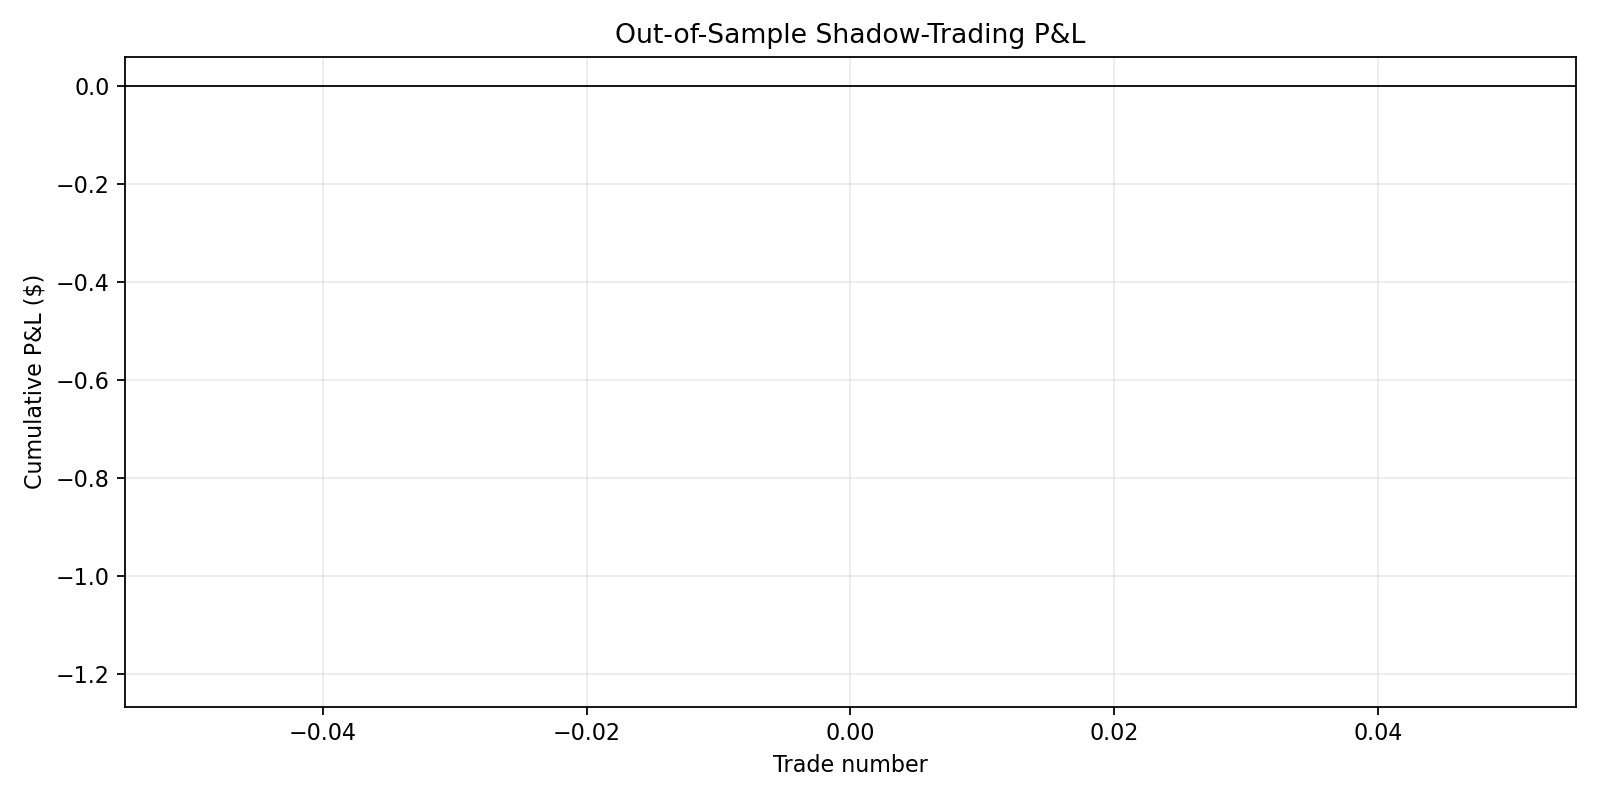

In [64]:
from IPython.display import Image, display

display(Image(filename=str(
    stage1_output / "test_equity_curve.png"
)))

In [65]:
feature_importance = pd.read_csv(
    stage1_output / "feature_importance.csv"
)

feature_importance.head(15)

,feature,long_importance,short_importance,mean_importance
0,cancellation_fraction_500,0.032884,0.003110,0.017997
1,execution_fraction_100,0.022651,0.007779,0.015215
2,trade_imbalance_500,0.012547,0.015900,0.014224
3,bid_gap_1_bps,0.023890,0.003481,0.013685
4,spread_bps,0.023890,0.003481,0.013685
5,ask_gap_1_bps,0.023890,0.003481,0.013685
6,trade_imbalance_20,0.013404,0.012473,0.012939
7,ask_gap_5_bps,0.001053,0.021379,0.011216
8,log_bid_depth_5,0.016654,0.003206,0.009930
9,event_rate_100,0.014700,0.000720,0.007710


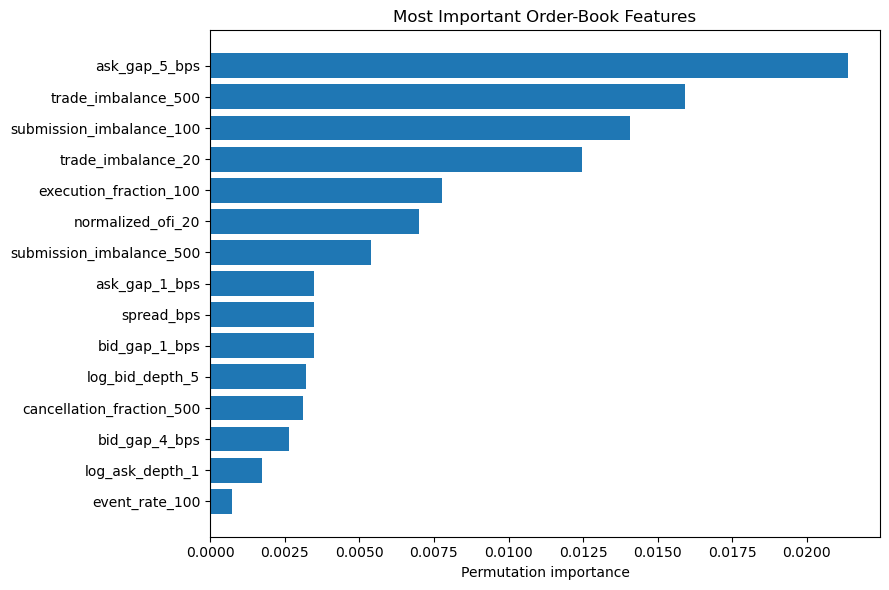

In [68]:
top_features = feature_importance.head(15).sort_values("short_importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["feature"],
    top_features["short_importance"],
)
plt.xlabel("Permutation importance")
plt.title("Most Important Order-Book Features")
plt.tight_layout()
plt.show()

In [57]:
threshold_sweep = pd.read_csv(
    research_output / "threshold_sweep.csv"
)

threshold_sweep

,threshold_bps,number_of_trades,net_pnl_dollars,average_trade_bps,median_trade_bps,win_rate,profit_factor,maximum_drawdown_dollars
0,0.180802,662,-1997.504888,-3.017379,-3.006780,0.010574,0.002795,-1995.188239
1,0.232251,617,-1861.472619,-3.016973,-3.008312,0.009724,0.002862,-1859.155969
2,0.295388,560,-1672.062405,-2.985826,-3.008436,0.007143,0.001443,-1669.745756
3,0.378779,461,-1353.337231,-2.935656,-3.007649,0.010846,0.001468,-1352.737231
4,0.508046,301,-856.884311,-2.846792,-2.834560,0.009967,0.002113,-853.880795
5,0.614168,193,-533.772041,-2.765658,-2.829960,0.015544,0.001455,-528.020942


In [102]:
# ============================================================
# MULTI-HORIZON PROFITABILITY DIAGNOSTIC
# ============================================================

from dataclasses import replace

# Horizons to test
horizons = [10, 25, 50, 100, 250, 500, 1000]

# Use the same base configuration as the main experiment
base_config = Config()

# Read LOBSTER data only once
raw = read_lobster(
    orderbook_path,
    message_path,
    base_config,
)

rows = []

for horizon in horizons:

    print(f"Testing horizon = {horizon} events...")

    # Same configuration, only change holding horizon
    horizon_config = replace(
        base_config,
        horizon_rows=horizon,
    )

    # Rebuild targets using this horizon
    frame_h, feature_names_h = build_research_frame(
        raw,
        horizon_config,
    )

    # Same purged chronological split used in run_research()
    purge = (
        horizon_config.latency_rows
        + horizon_config.horizon_rows
    )

    (
        train_index,
        validation_index,
        test_index,
    ) = chronological_splits(
        len(frame_h),
        purge,
    )

    # IMPORTANT:
    # Use validation only -- do not inspect test when selecting horizon
    validation_h = frame_h.iloc[validation_index]

    long_returns = validation_h[
        "long_net_return_bps"
    ].to_numpy()

    short_returns = validation_h[
        "short_net_return_bps"
    ].to_numpy()

    mid_returns = validation_h[
        "target_mid_bps"
    ].to_numpy()

    rows.append(
        {
            "horizon_events": horizon,

            "validation_rows": len(validation_h),

            # LONG
            "mean_long_net_bps": long_returns.mean(),
            "median_long_net_bps": np.median(long_returns),
            "long_profitable_fraction": np.mean(
                long_returns > 0
            ),

            # SHORT
            "mean_short_net_bps": short_returns.mean(),
            "median_short_net_bps": np.median(short_returns),
            "short_profitable_fraction": np.mean(
                short_returns > 0
            ),

            # Underlying midpoint movement
            "mean_abs_mid_move_bps": np.mean(
                np.abs(mid_returns)
            ),

            # Does either direction make money at this snapshot?
            "either_side_profitable_fraction": np.mean(
                (long_returns > 0)
                | (short_returns > 0)
            ),

            # Best possible direction with hindsight
            # Diagnostic only -- NOT a tradable result
            "oracle_mean_best_net_bps": np.mean(
                np.maximum(
                    long_returns,
                    short_returns,
                )
            ),
        }
    )


horizon_diagnostic = pd.DataFrame(rows)

# Make percentages easier to read
horizon_diagnostic[
    "long_profitable_pct"
] = (
    100
    * horizon_diagnostic["long_profitable_fraction"]
)

horizon_diagnostic[
    "short_profitable_pct"
] = (
    100
    * horizon_diagnostic["short_profitable_fraction"]
)

horizon_diagnostic[
    "either_side_profitable_pct"
] = (
    100
    * horizon_diagnostic["either_side_profitable_fraction"]
)


# Display the most useful columns
display(
    horizon_diagnostic[
        [
            "horizon_events",
            "validation_rows",
            "mean_abs_mid_move_bps",
            "mean_long_net_bps",
            "long_profitable_pct",
            "mean_short_net_bps",
            "short_profitable_pct",
            "either_side_profitable_pct",
            "oracle_mean_best_net_bps",
        ]
    ]
)

Testing horizon = 10 events...
Testing horizon = 25 events...
Testing horizon = 50 events...
Testing horizon = 100 events...
Testing horizon = 250 events...
Testing horizon = 500 events...
Testing horizon = 1000 events...


,horizon_events,validation_rows,mean_abs_mid_move_bps,mean_long_net_bps,long_profitable_pct,mean_short_net_bps,short_profitable_pct,either_side_profitable_pct,oracle_mean_best_net_bps
0,10,79946,0.220775,-2.759692,0.005003,-2.753296,0.020014,0.025017,-2.536158
1,25,79927,0.407445,-2.764645,0.031279,-2.747827,0.120110,0.151388,-2.349004
2,50,79897,0.628940,-2.772820,0.286619,-2.738652,0.534438,0.821057,-2.126530
3,100,79838,0.972832,-2.790138,2.144342,-2.720534,2.491295,4.635637,-1.782561
4,250,79657,1.649053,-2.835146,10.107084,-2.673724,10.877889,20.984973,-1.099092
5,500,79357,2.357662,-2.915084,16.772307,-2.593898,20.624520,37.396827,-0.388802
6,1000,78757,3.185182,-3.067560,23.656310,-2.433344,26.589383,50.245692,0.445996


In [124]:
# ============================================================
# H = 1000: LONG / SHORT / NO-TRADE CLASS DIAGNOSTIC
# ============================================================

from dataclasses import replace

# Use the same base configuration, but with H = 1000
class_config = replace(base_config,horizon_rows=1000,)

# Rebuild the execution-aware frame at H = 1000
frame_1000, feature_names_1000 = build_research_frame(raw,class_config,)

# Same purged chronological split used everywhere else
purge_1000 = (class_config.latency_rows+ class_config.horizon_rows)

(train_index_1000,validation_index_1000,test_index_1000,) = chronological_splits(len(frame_1000),
    purge_1000,)

# IMPORTANT:
# inspect validation only
validation_1000 = frame_1000.iloc[validation_index_1000].copy()


# Actual executable returns
long_return = validation_1000["long_net_return_bps"].to_numpy()

short_return = validation_1000["short_net_return_bps"].to_numpy()


# ============================================================
# CREATE THE 3-CLASS TARGET
#
# +1 = profitable long is best
# -1 = profitable short is best
#  0 = neither side is profitable
# ============================================================

trade_class = np.zeros(len(validation_1000),dtype=int,)

long_mask = ((long_return > 0) & (long_return >= short_return))

short_mask = ((short_return > 0) & (short_return > long_return))

trade_class[long_mask] = 1
trade_class[short_mask] = -1


# ============================================================
# DIAGNOSTIC
# ============================================================

number_long = np.sum(trade_class == 1)
number_short = np.sum(trade_class == -1)
number_no_trade = np.sum(trade_class == 0)

total = len(trade_class)

print("=" * 60)
print("H = 1000 CLASS DISTRIBUTION")
print("=" * 60)

print(f"Validation rows: {total}")

print(f"\nLONG (+1):     {number_long}"f"  ({number_long / total:.2%})")

print(f"SHORT (-1):    {number_short}" f"  ({number_short / total:.2%})")

print(f"NO TRADE (0):  {number_no_trade}" f"  ({number_no_trade / total:.2%})")


# ============================================================
# RETURNS WITHIN EACH CLASS
# ============================================================

if number_long > 0:

    print("\nMean long executable return " "inside LONG class:")

    print(f"{long_return[trade_class == 1].mean():.4f} bps")


if number_short > 0:

    print("\nMean short executable return " "inside SHORT class:")

    print(f"{short_return[trade_class == -1].mean():.4f} bps")


# Best achievable executable return at each row
best_executable_return = np.maximum(long_return, short_return,)

print("\nMean best executable return " "when class is trade:")

trade_rows = trade_class != 0

print(f"{best_executable_return[trade_rows].mean():.4f} bps")


print("\nMean best executable return " "when class is NO TRADE:")

print(f"{best_executable_return[~trade_rows].mean():.4f} bps")

H = 1000 CLASS DISTRIBUTION
Validation rows: 78757

LONG (+1):     18631  (23.66%)
SHORT (-1):    20941  (26.59%)
NO TRADE (0):  39185  (49.75%)

Mean long executable return inside LONG class:
2.1666 bps

Mean short executable return inside SHORT class:
2.6612 bps

Mean best executable return when class is trade:
2.4284 bps

Mean best executable return when class is NO TRADE:
-1.5559 bps


In [125]:
frame_1000
feature_names_1000
train_index_1000
validation_index_1000
test_index_1000
class_config

Config(level=5, event_stride=1, latency_rows=10, horizon_rows=1000, commission_bps_per_side=0.0, slippage_ticks_per_side=1.0, tick_size_dollars=0.01, notional_dollars=10000.0, minimum_validation_trades=5, flow_windows=(20, 100, 500), random_state=42, chunk_size=500000)

In [119]:
# ============================================================
# PASSIVE FILL-RATE DIAGNOSTIC
# ============================================================

print("=" * 60)
print("PASSIVE ENTRY FILL DIAGNOSTIC")
print("=" * 60)

print(
    "Passive BUY fill rate:",
    f"{validation_1000['passive_buy_filled'].mean():.2%}"
)

print(
    "Passive SELL fill rate:",
    f"{validation_1000['passive_sell_filled'].mean():.2%}"
)


buy_fills = validation_1000[
    validation_1000[
        "passive_buy_filled"
    ] == 1
]

sell_fills = validation_1000[
    validation_1000[
        "passive_sell_filled"
    ] == 1
]


if len(buy_fills) > 0:

    print(
        "\nMean events until BUY fill:",
        buy_fills[
            "passive_buy_fill_events"
        ].mean()
    )

    print(
        "Median events until BUY fill:",
        buy_fills[
            "passive_buy_fill_events"
        ].median()
    )


if len(sell_fills) > 0:

    print(
        "\nMean events until SELL fill:",
        sell_fills[
            "passive_sell_fill_events"
        ].mean()
    )

    print(
        "Median events until SELL fill:",
        sell_fills[
            "passive_sell_fill_events"
        ].median()
    )

PASSIVE ENTRY FILL DIAGNOSTIC
Passive BUY fill rate: 0.45%
Passive SELL fill rate: 0.37%

Mean events until BUY fill: 100.0
Median events until BUY fill: 100.0

Mean events until SELL fill: 100.0
Median events until SELL fill: 100.0


In [120]:
pd.DataFrame(
    {
        "side": [
            "passive buy",
            "passive sell",
        ],

        "fill_rate": [
            validation_1000[
                "passive_buy_filled"
            ].mean(),

            validation_1000[
                "passive_sell_filled"
            ].mean(),
        ],

        "mean_fill_events": [
            buy_fills[
                "passive_buy_fill_events"
            ].mean(),

            sell_fills[
                "passive_sell_fill_events"
            ].mean(),
        ],

        "median_fill_events": [
            buy_fills[
                "passive_buy_fill_events"
            ].median(),

            sell_fills[
                "passive_sell_fill_events"
            ].median(),
        ],
    }
)

,side,fill_rate,mean_fill_events,median_fill_events
0,passive buy,0.004508,100.0,100.0
1,passive sell,0.003746,100.0,100.0


In [126]:
print("BUY fill-event counts:")
print(
    validation_1000.loc[
        validation_1000["passive_buy_filled"] == 1,
        "passive_buy_fill_events"
    ].value_counts().sort_index()
)

print("\nSELL fill-event counts:")
print(
    validation_1000.loc[
        validation_1000["passive_sell_filled"] == 1,
        "passive_sell_fill_events"
    ].value_counts().sort_index()
)

BUY fill-event counts:
passive_buy_fill_events
101.0    78757
Name: count, dtype: int64

SELL fill-event counts:
passive_sell_fill_events
101.0    78757
Name: count, dtype: int64


In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,confusion_matrix,)
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [111]:
# ============================================================
# CREATE H=1000 THREE-CLASS TARGET FOR THE ENTIRE DATASET
#
# +1 = LONG
#  0 = NO TRADE
# -1 = SHORT
# ============================================================

long_return_all = frame_1000["long_net_return_bps"].to_numpy()

short_return_all = frame_1000["short_net_return_bps"].to_numpy()


trade_class_all = np.zeros(len(frame_1000),dtype=int,)


# Profitable long and better than short
long_mask_all = ((long_return_all > 0) & (long_return_all >= short_return_all))


# Profitable short and better than long
short_mask_all = ((short_return_all > 0) & (short_return_all > long_return_all))


trade_class_all[long_mask_all] = 1
trade_class_all[short_mask_all] = -1


# Store target in dataframe
frame_1000 = frame_1000.copy()

frame_1000["trade_class"] = trade_class_all


# Same chronological subsets
train_1000 = frame_1000.iloc[train_index_1000].copy()

validation_1000 = frame_1000.iloc[validation_index_1000].copy()

test_1000 = frame_1000.iloc[test_index_1000].copy()


# Check
print(
    "trade_class in train:",
    "trade_class" in train_1000.columns
)

print(
    "trade_class in validation:",
    "trade_class" in validation_1000.columns
)

print(
    "trade_class in test:",
    "trade_class" in test_1000.columns
)

print("Train:")
print(train_1000["trade_class"].value_counts(normalize=True).sort_index())

print("\nValidation:")
print(validation_1000["trade_class"].value_counts(normalize=True).sort_index())

trade_class in train: True
trade_class in validation: True
trade_class in test: True
Train:
trade_class
-1    0.256194
 0    0.534319
 1    0.209487
Name: proportion, dtype: float64

Validation:
trade_class
-1    0.265894
 0    0.497543
 1    0.236563
Name: proportion, dtype: float64


In [88]:
# ============================================================
# CLASSIFICATION MODEL CANDIDATES
# ============================================================

def make_classifier_candidates(config):

    return {

        "logistic": make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=config.random_state,
            ),
        ),

        "hist_gradient_boosting": (
            HistGradientBoostingClassifier(
                learning_rate=0.05,
                max_iter=150,
                max_leaf_nodes=31,
                min_samples_leaf=100,
                l2_regularization=1.0,
                random_state=config.random_state,
            )
        ),

        "random_forest": (
            RandomForestClassifier(
                n_estimators=150,
                max_depth=12,
                min_samples_leaf=100,
                max_features=0.70,
                class_weight="balanced",
                n_jobs=-1,
                random_state=config.random_state,
            )
        ),
    }

In [89]:
# ============================================================
# THREE-CLASS EXECUTION SIMULATOR
# ============================================================

def simulate_classifier_trades(
    block,
    probabilities,
    classes,
    probability_threshold,
    config,
):

    trades = []

    next_available_event = -np.inf

    event_occupation = (
        config.latency_rows
        + config.horizon_rows
    ) * config.event_stride


    # Find probability column belonging to each class
    class_to_column = {
        int(label): i
        for i, label in enumerate(classes)
    }

    p_short = probabilities[
        :, class_to_column[-1]
    ]

    p_no_trade = probabilities[
        :, class_to_column[0]
    ]

    p_long = probabilities[
        :, class_to_column[1]
    ]


    for row_number, (_, row) in enumerate(
        block.iterrows()
    ):

        event_number = int(
            row["event_number"]
        )

        # Don't allow overlapping positions
        if event_number < next_available_event:
            continue


        long_probability = p_long[row_number]
        short_probability = p_short[row_number]
        no_trade_probability = p_no_trade[row_number]


        # ----------------------------------------
        # LONG decision
        # ----------------------------------------

        if (
            long_probability
            >= probability_threshold
            and long_probability
            > no_trade_probability
            and long_probability
            >= short_probability
        ):

            side = 1

            realized_return = float(
                row["long_net_return_bps"]
            )

            selected_probability = (
                long_probability
            )


        # ----------------------------------------
        # SHORT decision
        # ----------------------------------------

        elif (
            short_probability
            >= probability_threshold
            and short_probability
            > no_trade_probability
            and short_probability
            > long_probability
        ):

            side = -1

            realized_return = float(
                row["short_net_return_bps"]
            )

            selected_probability = (
                short_probability
            )


        # ----------------------------------------
        # NO TRADE
        # ----------------------------------------

        else:
            continue


        trades.append(
            {
                "signal_event_number":
                    event_number,

                "signal_event_time":
                    row["seconds"],

                "side":
                    side,

                "predicted_probability":
                    selected_probability,

                "prob_long":
                    long_probability,

                "prob_short":
                    short_probability,

                "prob_no_trade":
                    no_trade_probability,

                "realized_net_return_bps":
                    realized_return,

                "net_return_bps":
                    realized_return,

                "pnl_dollars":
                    (
                        config.notional_dollars
                        * realized_return
                        / 10_000
                    ),
            }
        )


        next_available_event = (
            event_number
            + event_occupation
        )


    return pd.DataFrame(trades)

In [108]:
# ============================================================
# PROBABILITY THRESHOLD SELECTION
# VALIDATION DATA ONLY
# ============================================================

def choose_classifier_threshold(
    validation_frame,
    probabilities,
    classes,
    config,
):

    thresholds = np.array([ 0.55,
        0.58,
        0.60,
        0.62,
        0.64,
        0.65,
        0.66,
        0.68,
        0.70,
        0.72,
        0.75,])

    rows = []

    for threshold in thresholds:

        trades = simulate_classifier_trades(
            block=validation_frame,
            probabilities=probabilities,
            classes=classes,
            probability_threshold=threshold,
            config=config,
        )

        metrics = trading_metrics(
            trades
        )

        rows.append(
            {
                "probability_threshold":
                    threshold,

                **metrics,
            }
        )


    sweep = pd.DataFrame(rows)


    # Prefer thresholds giving a reasonable
    # number of validation trades
    eligible = sweep[
        sweep["number_of_trades"]
        >= config.minimum_validation_trades
    ]


    if eligible.empty:
        eligible = sweep


    best = eligible.sort_values(
        [
            "net_pnl_dollars",
            "average_trade_bps",
        ],
        ascending=False,
    ).iloc[0]


    return (
        float(
            best["probability_threshold"]
        ),
        sweep,
    )

In [109]:
print("base_config minimum trades:",
      base_config.minimum_validation_trades)

print("class_config minimum trades:",
      class_config.minimum_validation_trades)

base_config minimum trades: 5
class_config minimum trades: 5


In [112]:
# ============================================================
# H=1000 COST-AWARE THREE-CLASS CLASSIFICATION
# ============================================================

classifier_candidates = (
    make_classifier_candidates(
        class_config
    )
)


X_train = train_1000[
    feature_names_1000
]

y_train = train_1000[
    "trade_class"
]


X_validation = validation_1000[
    feature_names_1000
]

y_validation = validation_1000[
    "trade_class"
]


classification_results = []

trained_classifiers = {}


for model_name, model_template in (
    classifier_candidates.items()
):

    print(
        f"\nTraining {model_name} classifier..."
    )

    model = clone(
        model_template
    )

    model.fit(
        X_train,
        y_train,
    )


    # ----------------------------------------
    # Validation predictions
    # ----------------------------------------

    validation_prediction = (
        model.predict(
            X_validation
        )
    )

    validation_probabilities = (
        model.predict_proba(
            X_validation
        )
    )


    accuracy = accuracy_score(
        y_validation,
        validation_prediction,
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            y_validation,
            validation_prediction,
        )
    )


    # ----------------------------------------
    # Select probability threshold
    # USING VALIDATION ONLY
    # ----------------------------------------

    (
        threshold,
        threshold_sweep,
    ) = choose_classifier_threshold(
        validation_frame=
            validation_1000,

        probabilities=
            validation_probabilities,

        classes=
            model.classes_,

        config=
            class_config,
    )


    validation_trades = (
        simulate_classifier_trades(
            block=
                validation_1000,

            probabilities=
                validation_probabilities,

            classes=
                model.classes_,

            probability_threshold=
                threshold,

            config=
                class_config,
        )
    )


    validation_trade_metrics = (
        trading_metrics(
            validation_trades
        )
    )


    classification_results.append(
        {
            "model":
                model_name,

            "accuracy":
                accuracy,

            "balanced_accuracy":
                balanced_accuracy,

            "probability_threshold":
                threshold,

            "number_of_trades":
                validation_trade_metrics[
                    "number_of_trades"
                ],

            "net_pnl_dollars":
                validation_trade_metrics[
                    "net_pnl_dollars"
                ],

            "average_trade_bps":
                validation_trade_metrics[
                    "average_trade_bps"
                ],

            "win_rate":
                validation_trade_metrics[
                    "win_rate"
                ],
        }
    )


    trained_classifiers[
        model_name
    ] = {
        "model":
            model,

        "threshold":
            threshold,

        "validation_probabilities":
            validation_probabilities,

        "validation_trades":
            validation_trades,

        "threshold_sweep":
            threshold_sweep,
    }


classifier_comparison = pd.DataFrame(
    classification_results
).sort_values(
    [
        "net_pnl_dollars",
        "average_trade_bps",
    ],
    ascending=False,
).reset_index(
    drop=True
)


display(
    classifier_comparison
)


Training logistic classifier...

Training hist_gradient_boosting classifier...

Training random_forest classifier...


,model,accuracy,balanced_accuracy,probability_threshold,number_of_trades,net_pnl_dollars,average_trade_bps,win_rate
0,logistic,0.330028,0.361444,0.70,5,-0.631783,-0.126357,0.600000
1,random_forest,0.369859,0.359702,0.75,6,-17.691769,-2.948628,0.166667
2,hist_gradient_boosting,0.454982,0.342067,0.75,17,-62.179437,-3.657614,0.176471


In [92]:
for model_name, result in trained_classifiers.items():

    print("\n", "=" * 60)
    print(model_name.upper())
    print("=" * 60)

    display(
        result["threshold_sweep"][
            [
                "probability_threshold",
                "number_of_trades",
                "net_pnl_dollars",
                "average_trade_bps",
                "win_rate",
            ]
        ]
    )


LOGISTIC


,probability_threshold,number_of_trades,net_pnl_dollars,average_trade_bps,win_rate
0,0.35,78,-192.069036,-2.462424,0.256410
1,0.40,77,-214.618004,-2.787247,0.233766
2,0.45,73,-190.158759,-2.604915,0.287671
3,0.50,63,-162.194061,-2.574509,0.253968
4,0.55,47,-92.923967,-1.977106,0.297872
5,0.60,18,-16.975393,-0.943077,0.444444
6,0.65,11,-9.449987,-0.859090,0.454545
7,0.70,5,-0.631783,-0.126357,0.600000
8,0.75,1,1.889742,1.889742,1.000000
9,0.80,0,0.000000,NaN,NaN



HIST_GRADIENT_BOOSTING


,probability_threshold,number_of_trades,net_pnl_dollars,average_trade_bps,win_rate
0,0.35,73,-152.646672,-2.091050,0.260274
1,0.40,72,-153.247747,-2.128441,0.250000
2,0.45,70,-178.995037,-2.557072,0.214286
3,0.50,67,-167.177443,-2.495186,0.283582
4,0.55,54,-148.619658,-2.752216,0.259259
5,0.60,49,-137.999515,-2.816317,0.224490
6,0.65,40,-105.723127,-2.643078,0.275000
7,0.70,24,-98.431862,-4.101328,0.208333
8,0.75,17,-62.179437,-3.657614,0.176471
9,0.80,10,-20.253888,-2.025389,0.300000



RANDOM_FOREST


,probability_threshold,number_of_trades,net_pnl_dollars,average_trade_bps,win_rate
0,0.35,78,-207.709854,-2.662947,0.256410
1,0.40,77,-168.698599,-2.190891,0.337662
2,0.45,73,-178.965381,-2.451581,0.287671
3,0.50,68,-172.537129,-2.537311,0.220588
4,0.55,57,-173.977522,-3.052237,0.228070
5,0.60,43,-126.497711,-2.941807,0.232558
6,0.65,23,-68.607648,-2.982941,0.130435
7,0.70,9,-34.474740,-3.830527,0.111111
8,0.75,6,-17.691769,-2.948628,0.166667
9,0.80,4,-9.327664,-2.331916,0.250000


In [93]:
# ============================================================
# LOGISTIC CONFIDENCE / REALIZED EDGE DIAGNOSTIC
# No position-overlap restriction -- diagnostic only
# ============================================================

logistic_result = trained_classifiers["logistic"]

logistic_model = logistic_result["model"]

logistic_probabilities = logistic_result[
    "validation_probabilities"
]

classes = logistic_model.classes_

class_to_column = {
    int(label): i
    for i, label in enumerate(classes)
}

p_short = logistic_probabilities[
    :, class_to_column[-1]
]

p_no_trade = logistic_probabilities[
    :, class_to_column[0]
]

p_long = logistic_probabilities[
    :, class_to_column[1]
]


# Model's preferred trading direction
predicted_side = np.where(
    p_long >= p_short,
    1,
    -1,
)

trade_probability = np.maximum(
    p_long,
    p_short,
)


# Realized executable return of the direction
# that the model preferred
realized_selected_return = np.where(
    predicted_side == 1,
    validation_1000[
        "long_net_return_bps"
    ].to_numpy(),
    validation_1000[
        "short_net_return_bps"
    ].to_numpy(),
)


rows = []

for threshold in [
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
]:

    mask = (
        (trade_probability >= threshold)
        & (trade_probability > p_no_trade)
    )

    if mask.sum() == 0:
        continue

    rows.append(
        {
            "threshold": threshold,
            "rows": mask.sum(),

            "fraction_of_validation":
                mask.mean(),

            "mean_realized_net_bps":
                realized_selected_return[
                    mask
                ].mean(),

            "median_realized_net_bps":
                np.median(
                    realized_selected_return[
                        mask
                    ]
                ),

            "win_rate":
                np.mean(
                    realized_selected_return[
                        mask
                    ] > 0
                ),

            "mean_confidence":
                trade_probability[
                    mask
                ].mean(),
        }
    )


confidence_diagnostic = pd.DataFrame(
    rows
)

display(confidence_diagnostic)

,threshold,rows,fraction_of_validation,mean_realized_net_bps,median_realized_net_bps,win_rate,mean_confidence
0,0.35,60686,0.770547,-2.422944,-2.580690,0.275302,0.427387
1,0.40,36944,0.469088,-2.269409,-2.580423,0.285351,0.459847
2,0.45,17091,0.217009,-2.236656,-2.661881,0.289451,0.503164
3,0.50,6783,0.086126,-2.193389,-2.666427,0.297508,0.550282
4,0.55,2560,0.032505,-1.372065,-1.546498,0.391406,0.599013
5,0.60,1034,0.013129,-0.198426,0.687876,0.549323,0.640175
6,0.65,289,0.003670,0.635639,1.546392,0.719723,0.686407
7,0.70,79,0.001003,0.897614,1.374570,0.886076,0.727056
8,0.75,5,0.000063,1.580639,1.374570,1.000000,0.773553


In [115]:
# ============================================================
# COST-ABLATION DIAGNOSTIC
# H = 1000, VALIDATION ONLY
# ============================================================

cost_ablation = pd.DataFrame(
    {
        "execution_model": [
            "A: midpoint / zero cost",
            "B: best bid-ask / spread only",
            "C: depth VWAP / zero extra slippage",
            "D: depth VWAP / +1 tick slippage",
        ],

        "mean_long_bps": [
            validation_1000[
                "mid_long_return_bps"
            ].mean(),

            validation_1000[
                "touch_long_return_bps"
            ].mean(),

            validation_1000[
                "depth_no_slip_long_bps"
            ].mean(),

            validation_1000[
                "long_net_return_bps"
            ].mean(),
        ],

        "mean_short_bps": [
            validation_1000[
                "mid_short_return_bps"
            ].mean(),

            validation_1000[
                "touch_short_return_bps"
            ].mean(),

            validation_1000[
                "depth_no_slip_short_bps"
            ].mean(),

            validation_1000[
                "short_net_return_bps"
            ].mean(),
        ],
    }
)


# Best direction with hindsight.
# DIAGNOSTIC ONLY — NOT A BACKTEST.
cost_ablation[
    "oracle_best_mean_bps"
] = [

    np.maximum(
        validation_1000["mid_long_return_bps"],
        validation_1000["mid_short_return_bps"],
    ).mean(),

    np.maximum(
        validation_1000["touch_long_return_bps"],
        validation_1000["touch_short_return_bps"],
    ).mean(),

    np.maximum(
        validation_1000["depth_no_slip_long_bps"],
        validation_1000["depth_no_slip_short_bps"],
    ).mean(),

    np.maximum(
        validation_1000["long_net_return_bps"],
        validation_1000["short_net_return_bps"],
    ).mean(),
]


display(cost_ablation)

,execution_model,mean_long_bps,mean_short_bps,oracle_best_mean_bps
0,A: midpoint / zero cost,-0.317249,0.317249,3.185182
1,B: best bid-ask / spread only,-2.640916,-2.007010,0.861195
2,C: depth VWAP / zero extra slippage,-2.723883,-2.089490,0.789767
3,D: depth VWAP / +1 tick slippage,-3.067560,-2.433344,0.445996
